In [16]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("station_day.csv")
df = df.drop(columns=['AQI_Bucket','Xylene'])
df.head()

,StationId,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI
0,AP001,2017-11-24,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92,NaN
1,AP001,2017-11-25,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50,184.0
2,AP001,2017-11-26,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95,197.0
3,AP001,2017-11-27,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63,198.0
4,AP001,2017-11-28,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02,188.0


In [4]:
df.shape

(108035, 14)

In [5]:
df.columns

Index(['StationId', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO',
       'SO2', 'O3', 'Benzene', 'Toluene', 'AQI'],
      dtype='str')

In [6]:
df.isnull().sum()

StationId        0
Date             0
PM2.5        21625
PM10         42706
NO           17106
NO2          16547
NOx          15500
NH3          48105
CO           12998
SO2          25204
O3           25568
Benzene      31455
Toluene      38702
AQI          21010
dtype: int64

In [7]:
pollutants = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
    'CO', 'SO2', 'O3', 'Benzene', 'Toluene']

df = df.dropna(subset=['AQI']).copy()

for col in pollutants:
    df[col] = df[col].fillna(df[col].median())

# Check remaining missing values
print(df[pollutants + ['AQI']].isnull().sum())

PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
AQI        0
dtype: int64


In [8]:
df.describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI
count,87025.000000,87025.000000,87025.000000,87025.000000,87025.000000,87025.000000,87025.000000,87025.00000,87025.000000,87025.000000,87025.000000,87025.000000
mean,79.416995,148.610429,22.910802,34.977047,42.458055,26.976453,1.593586,11.86730,37.501031,3.069497,13.154947,179.749290
std,74.575227,106.440785,34.284270,28.781179,44.316270,19.606079,4.184997,11.80353,37.399769,10.147303,25.854835,131.324339
min,0.040000,0.030000,0.020000,0.010000,0.000000,0.010000,0.000000,0.01000,0.010000,0.000000,0.000000,8.000000
25%,32.960000,89.370000,4.920000,15.390000,16.160000,18.000000,0.610000,5.53000,20.420000,0.480000,2.300000,86.000000
50%,56.170000,122.430000,10.220000,27.240000,28.180000,23.760000,0.950000,9.06000,30.890000,1.380000,5.310000,132.000000
75%,97.330000,167.020000,24.180000,46.290000,50.470000,29.740000,1.440000,13.96000,44.660000,2.830000,10.750000,254.000000
max,1000.000000,976.770000,437.850000,448.050000,434.900000,365.680000,175.810000,186.08000,963.000000,455.030000,454.850000,2049.000000


In [9]:
x = df.drop(columns=['StationId', 'Date', 'AQI'])
y = df['AQI']

In [10]:
x.head()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
1,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50
2,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95
3,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63
4,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02
5,72.47,114.84,5.23,23.20,16.59,12.25,0.16,10.55,109.74,0.21,4.71


In [11]:
print(f"X Shape:{x.shape}")
print(f"Y Shape:{y.shape}")

X Shape:(87025, 11)
Y Shape:(87025,)


In [12]:
x_train1,x_test1,y_train1,y_test1 = train_test_split(x,y,train_size=0.8,random_state=42)

scaler = MinMaxScaler()
x_train_scaled1 = scaler.fit_transform(x_train1)
x_test_scaled1 = scaler.transform(x_test1)

print(f"x_train Shape:{x_train_scaled1.shape}")
print(f"x_test Shape:{x_test_scaled1.shape}")
print(f"y_train Shape:{y_train1.shape}")
print(f"y_test Shape:{y_test1.shape}")

x_train Shape:(69620, 11)
x_test Shape:(17405, 11)
y_train Shape:(69620,)
y_test Shape:(17405,)


In [13]:
lr = LinearRegression()

lr = lr.fit(x_train_scaled1,y_train1)
y_pred1 = lr.predict(x_test_scaled1)

print(f" Coefficient: {lr.coef_}\n")
print(f" Intercept: {lr.intercept_}")

 Coefficient: [1006.27304928  285.31402632  -44.75698852   54.34982404   54.16127437
    8.78052984 1546.60710124  156.47343454  199.74478374   17.31290354
  -30.25563225]

 Intercept: 14.03891544231027


In [14]:
print(f"Mean Absolute Error: {mean_absolute_error(y_test1,y_pred1)}")
print(f"Mean Squared Error: {mean_squared_error(y_test1,y_pred1)}")
print(f"R2 Score: {r2_score(y_test1,y_pred1)}")

Mean Absolute Error: 35.62649956768478
Mean Squared Error: 2883.201295649905
R2 Score: 0.8329867635494352


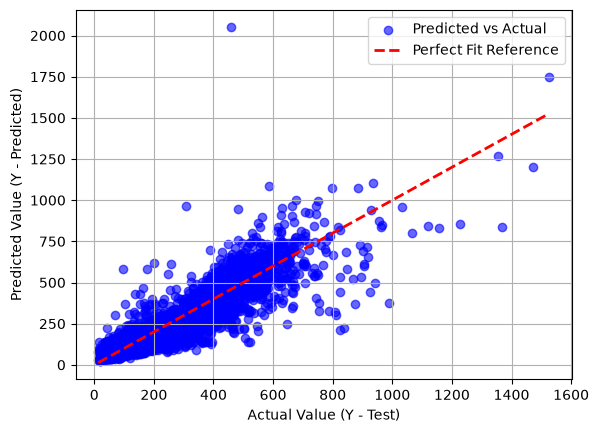

In [15]:
plt.scatter(y_test1, y_pred1, color='blue', alpha=0.6, label='Predicted vs Actual')

ideal_line = [min(y_test1), max(y_test1)]
plt.plot(ideal_line, ideal_line, color='red', linestyle='--', linewidth=2, label='Perfect Fit Reference')
plt.xlabel('Actual Value (Y - Test)')
plt.ylabel('Predicted Value (Y - Predicted)')
plt.legend()
plt.grid(True)

plt.show()

In [15]:
poly = PolynomialFeatures(degree=2)

x_train2, x_test2, y_train2, y_test2 = train_test_split(x,y, train_size=0.8, random_state=42)

x_train_scaled2 = scaler.fit_transform(x_train2)
x_test_scaled2 = scaler.transform(x_test2)

x_train_poly = poly.fit_transform(x_train_scaled2)
x_test_poly = poly.transform(x_test_scaled2)

lr2 = LinearRegression()
lr2.fit(x_train_poly,y_train2)

y_pred2 = lr2.predict(x_test_poly)

print(f" Coefficient: {lr2.coef_}\n")
print(f" Intercept: {lr2.intercept_}")

 Coefficient: [-2.04323917e-13  1.72022922e+03  1.46250189e+02  9.46398178e+01
  3.36754745e+01  3.49572248e+01 -5.28337163e+00  1.96604295e+03
  1.40253435e+02  4.33923431e+02  6.93674153e+00  3.33639550e+01
 -9.38050110e+02 -1.30979803e+03 -2.62822563e+02  1.06165562e+03
 -6.79044712e+02  4.70756842e+02 -9.49445244e+02 -3.05544104e+02
 -1.06776474e+03  2.45543467e+01 -3.24886048e+02  6.77747920e+02
 -2.29896545e+02 -5.95179094e+02  3.39815491e+02  2.74052906e+01
 -2.58344881e+03  2.97197866e+02 -3.99735970e+02  3.09677716e+02
  1.95512630e+02  4.68269632e+00 -2.90337616e+01 -4.48491909e+01
 -1.19522325e+02  2.92564415e+03 -1.91992972e+02 -7.18960124e+02
  7.00540151e+01  2.09389213e+02 -8.60116246e+01 -1.04584670e+02
  1.50146966e+01  1.55077467e+03 -7.04679267e+01 -3.08995630e+02
  7.20053311e+02 -1.29073491e+02  1.20841714e+02  1.59668177e+02
  2.92631055e+02 -3.85166902e+02  2.91302185e+02 -4.10036392e+02
 -3.69283366e+02 -5.74823436e+01 -4.07023058e+03  1.35362624e+02
  2.8966121

In [16]:
print(f"Mean Absolute Error: {mean_absolute_error(y_test2,y_pred2)}")
print(f"Mean Squared Error: {mean_squared_error(y_test2,y_pred2)}")
print(f"R2 Score: {r2_score(y_test2,y_pred2)}")

Mean Absolute Error: 30.68001697364607
Mean Squared Error: 2140.659525790257
R2 Score: 0.8759994745839023


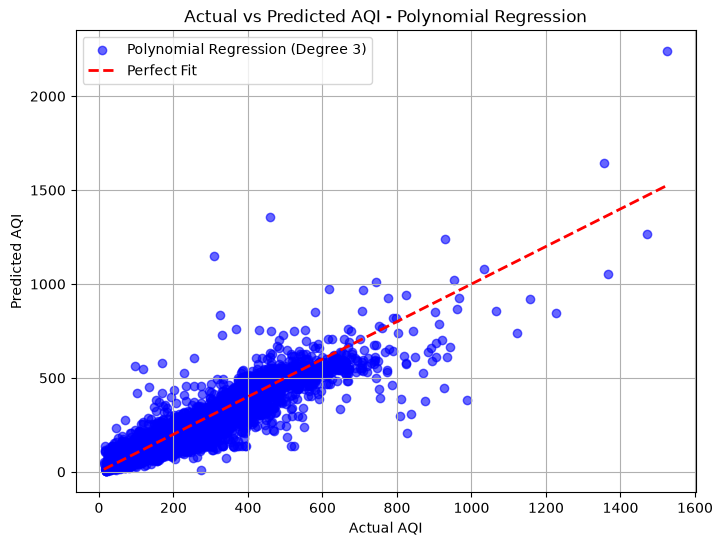

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test2, y_pred2,
    color='blue', alpha=0.6,
    label='Polynomial Regression (Degree 2)'
)

ideal_line = [min(y_test2), max(y_test2)]
plt.plot(
    ideal_line, ideal_line,
    color='red', linestyle='--',
    linewidth=2, label='Perfect Fit'
)

plt.xlabel('Actual AQI')
plt.ylabel('Predicted AQI')
plt.title('Actual vs Predicted AQI - Polynomial Regression')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Split data
x_train3, x_test3, y_train3, y_test3 = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

# Create pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("lr" , LinearRegression())
])

# Hyperparameters to test
param_grid = {
    "poly__degree": [1, 2, 3],
}

# Grid Search + 5-Fold Cross Validation
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train
grid_search.fit(x_train3, y_train3)

# Best model
best_model = grid_search.best_estimator_

# Best parameters
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation R²:")
print(grid_search.best_score_)

# Test prediction
y_pred3 = best_model.predict(x_test3)

# Evaluation
mae = mean_absolute_error(y_test3, y_pred3)
mse = mean_squared_error(y_test3, y_pred3)
rmse = np.sqrt(mse)
r2 = r2_score(y_test3, y_pred3)

print("\nTest Set Results:")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

Best Parameters:
{'poly__degree': 3}

Best Cross-Validation R²:
0.8796996900196424

Test Set Results:
MAE : 29.324788020305228
MSE : 2377.6827474353618
RMSE: 48.76148836361911
R²  : 0.8622695919632837


In [20]:
import joblib

model_bundle = {
    "scaler": scaler,
    "poly": poly,
    "model": lr2,
    "best_model": best_model,
    "features": list(x_train2.columns),
    "ranges": {
        col: {
            "min": float(x_train2[col].min()),
            "max": float(x_train2[col].max())
        }
        for col in x_train2.columns
    }
}

joblib.dump(model_bundle, "aqi_model.pkl")

['aqi_model.pkl']

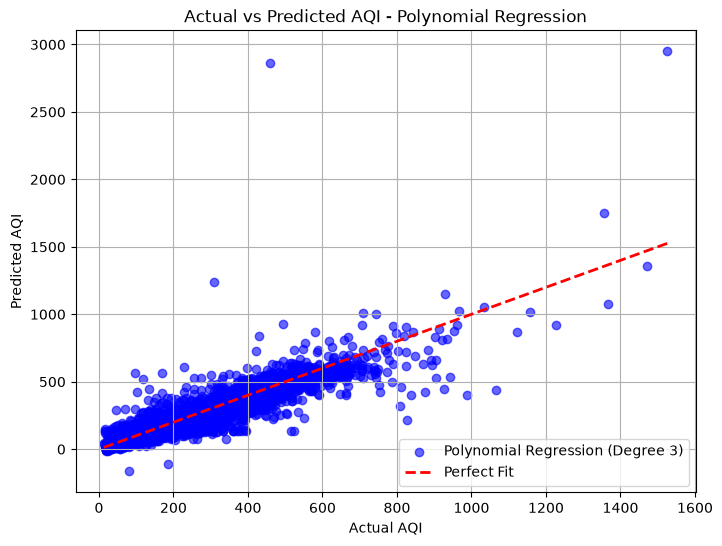

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test3, y_pred3,
    color='blue', alpha=0.6,
    label='Polynomial Regression (Degree 3)'
)

ideal_line = [min(y_test3), max(y_test3)]
plt.plot(
    ideal_line, ideal_line,
    color='red', linestyle='--',
    linewidth=2, label='Perfect Fit'
)

plt.xlabel('Actual AQI')
plt.ylabel('Predicted AQI')
plt.title('Actual vs Predicted AQI - Polynomial Regression')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
pm25 = float(input("Enter PM2.5: "))
pm10 = float(input("Enter PM10: "))
no = float(input("Enter NO: "))
no2 = float(input("Enter NO2: "))
nox = float(input("Enter NOx: "))
nh3 = float(input("Enter NH3: "))
co = float(input("Enter CO: "))
so2 = float(input("Enter SO2: "))
o3 = float(input("Enter O3: "))
benzene = float(input("Enter Benzene: "))
toluene = float(input("Enter Toluene: "))

# Keep the same feature order used during training.
user_input = pd.DataFrame([[
    pm25, pm10, no, no2, nox, nh3,
    co, so2, o3, benzene, toluene
]], columns=x.columns)

# lr2 was trained on MinMax-scaled, degree-2 polynomial features.
user_scaled = scaler.transform(user_input)
user_poly = poly.transform(user_scaled)
predicted_aqi_lr2 = lr2.predict(user_poly)[0]

# best_model is a pipeline that applies its own scaling and polynomial features.
predicted_aqi_best = best_model.predict(user_input)[0]

print(f"\nPolynomial model (lr2) predicted AQI: {predicted_aqi_lr2:.2f}")
print(f"Optimized model (best_model) predicted AQI: {predicted_aqi_best:.2f}")
